# Projet Deep Learning — Reconnaissance automatique de panneaux de signalisation

**Fondamentaux du Deep Learning — Master S1 — 2026-2027**

**Auteur :** OUESLATI Salim 



In [1]:
import os, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import confusion_matrix, f1_score

SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow :", tf.__version__)
print("GPU        :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.21.0
GPU        : []


# Partie 1 — Recherche, compréhension et préparation des données

## 1.1 Choix et description du dataset

**Dataset retenu : GTSRB — German Traffic Sign Recognition Benchmark.**

- **Source :** https://benchmark.ini.rub.de/gtsrb_dataset.html
- **Pourquoi ce choix :** 43 classes, des images réelles prises dans des conditions variées (luminosité, flou, angle, taille), format standard pour la classification multiclasse. Le benchmark complet compte plus de 50 000 images ; la version téléchargée ici (`torchvision`) en contient **39 270** (26 640 en entraînement + 12 630 en test).


> **Point méthodologique important.** Dans GTSRB, chaque panneau physique est photographié ~30 fois de suite (une « piste » / *track*). Si on mélange les images au hasard pour faire train / validation, des images quasi identiques d'un même panneau se retrouvent des deux côtés et la validation est **optimiste** (fuite de données). On découpe donc **par piste**, pas par image.

In [2]:
from torchvision import datasets

IMG = 32  # taille cible des images (IMG x IMG)

CLASS_NAMES = [
    "Limitation 20 km/h", "Limitation 30 km/h", "Limitation 50 km/h", "Limitation 60 km/h",
    "Limitation 70 km/h", "Limitation 80 km/h", "Fin de limitation 80 km/h", "Limitation 100 km/h",
    "Limitation 120 km/h", "Interdiction de dépasser", "Interdiction de dépasser (poids lourds)",
    "Priorité à la prochaine intersection", "Route prioritaire", "Cédez le passage", "STOP",
    "Circulation interdite", "Interdit aux poids lourds", "Sens interdit", "Danger général",
    "Virage dangereux à gauche", "Virage dangereux à droite", "Succession de virages",
    "Chaussée déformée", "Chaussée glissante", "Chaussée rétrécie à droite", "Travaux",
    "Feux tricolores", "Passage piétons", "Enfants", "Cyclistes", "Risque de verglas",
    "Passage d'animaux sauvages", "Fin de toutes interdictions", "Tourner à droite obligatoire",
    "Tourner à gauche obligatoire", "Tout droit obligatoire", "Tout droit ou à droite",
    "Tout droit ou à gauche", "Contourner par la droite", "Contourner par la gauche",
    "Rond-point obligatoire", "Fin interdiction de dépasser", "Fin interdiction de dépasser (poids lourds)",
]
NUM_CLASSES = len(CLASS_NAMES)  # K = 43


def load_split(split):
    # Télécharge (si besoin) puis charge toutes les images en mémoire, redimensionnées en IMG x IMG.
    ds = datasets.GTSRB(root="data", split=split, download=True)
    samples = getattr(ds, "_samples", None)  # liste (chemin, label) : sert à retrouver la piste
    X, y, sizes, groups = [], [], [], []
    for i in range(len(ds)):
        img, label = ds[i]
        sizes.append(img.size)  # (largeur, hauteur) ORIGINALES
        X.append(np.asarray(img.convert("RGB").resize((IMG, IMG), Image.BILINEAR), dtype=np.uint8))
        y.append(label)
        if samples is not None:
            # fichier "00007_00012.ppm" : 00007 = numéro de piste, 00012 = numéro d'image dans la piste
            groups.append(f"{label}_{os.path.basename(samples[i][0]).split('_')[0]}")
    return np.stack(X), np.array(y), np.array(sizes), (np.array(groups) if groups else None)


t0 = time.time()
X_full, y_full, sizes_full, groups_full = load_split("train")
X_test_u8, y_test, sizes_test, _ = load_split("test")
print(f"Chargement : {time.time() - t0:.0f} s")
print("Train+val :", X_full.shape, y_full.shape, "| dtype", X_full.dtype)
print("Test      :", X_test_u8.shape, y_test.shape)
assert set(y_full) == set(range(NUM_CLASSES)), "Le nombre de classes ne correspond pas à CLASS_NAMES"
print("Pistes distinctes (train) :", None if groups_full is None else len(set(groups_full)))

Chargement : 274 s
Train+val : (26640, 32, 32, 3) (26640,) | dtype uint8
Test      : (12630, 32, 32, 3) (12630,)
Pistes distinctes (train) : 888


Total images (train+val) : 26640 | test : 12630 | total : 39270
Classe la plus fréquente : 1 (1500 images) | la plus rare : 0 (150 images) | rapport : 10.0x


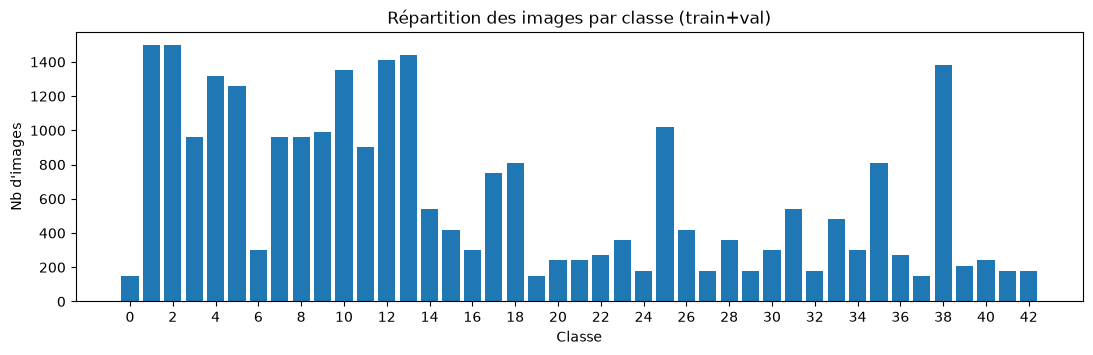

,classe,nb images (train+val),nb images (test)
0,0 - Limitation 20 km/h,150,60
1,1 - Limitation 30 km/h,1500,720
2,2 - Limitation 50 km/h,1500,750
3,3 - Limitation 60 km/h,960,450
4,4 - Limitation 70 km/h,1320,660
5,5 - Limitation 80 km/h,1260,630
6,6 - Fin de limitation 80 km/h,300,150
7,7 - Limitation 100 km/h,960,450
8,8 - Limitation 120 km/h,960,450
9,9 - Interdiction de dépasser,990,480


In [3]:
# Nombre d'images par classe + déséquilibre
counts = pd.Series(y_full).value_counts().sort_index()
print(f"Total images (train+val) : {len(y_full)} | test : {len(y_test)} | total : {len(y_full) + len(y_test)}")
print(f"Classe la plus fréquente : {counts.idxmax()} ({counts.max()} images) | "
      f"la plus rare : {counts.idxmin()} ({counts.min()} images) | rapport : {counts.max() / counts.min():.1f}x")

plt.figure(figsize=(13, 3.5))
plt.bar(counts.index, counts.values)
plt.xlabel("Classe"); plt.ylabel("Nb d'images"); plt.title("Répartition des images par classe (train+val)")
plt.xticks(range(0, NUM_CLASSES, 2)); plt.show()

display(pd.DataFrame({"classe": [f"{i} - {CLASS_NAMES[i]}" for i in range(NUM_CLASSES)],
                      "nb images (train+val)": counts.values,
                      "nb images (test)": pd.Series(y_test).value_counts().sort_index().values}))

Largeur : min 25, médiane 43, max 243 px
Hauteur : min 25, médiane 43, max 225 px
Format des fichiers : .ppm, images couleur RGB (3 canaux), pixels uint8 (0-255)
Après redimensionnement : (32, 32, 3) -> même taille pour toutes les images


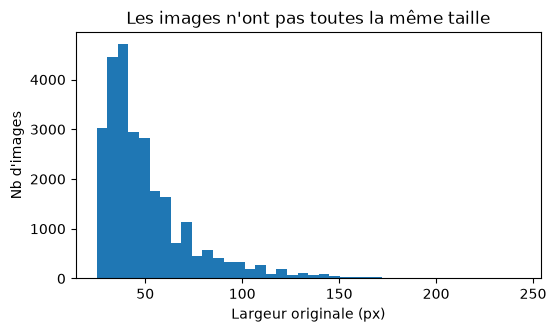

In [4]:
# Dimensions et format des images ORIGINALES (avant redimensionnement)
w, h = sizes_full[:, 0], sizes_full[:, 1]
print(f"Largeur : min {w.min()}, médiane {int(np.median(w))}, max {w.max()} px")
print(f"Hauteur : min {h.min()}, médiane {int(np.median(h))}, max {h.max()} px")
print("Format des fichiers : .ppm, images couleur RGB (3 canaux), pixels uint8 (0-255)")
print("Après redimensionnement :", X_full.shape[1:], "-> même taille pour toutes les images")

plt.figure(figsize=(6, 3.2))
plt.hist(w, bins=40); plt.xlabel("Largeur originale (px)"); plt.ylabel("Nb d'images")
plt.title("Les images n'ont pas toutes la même taille"); plt.show()

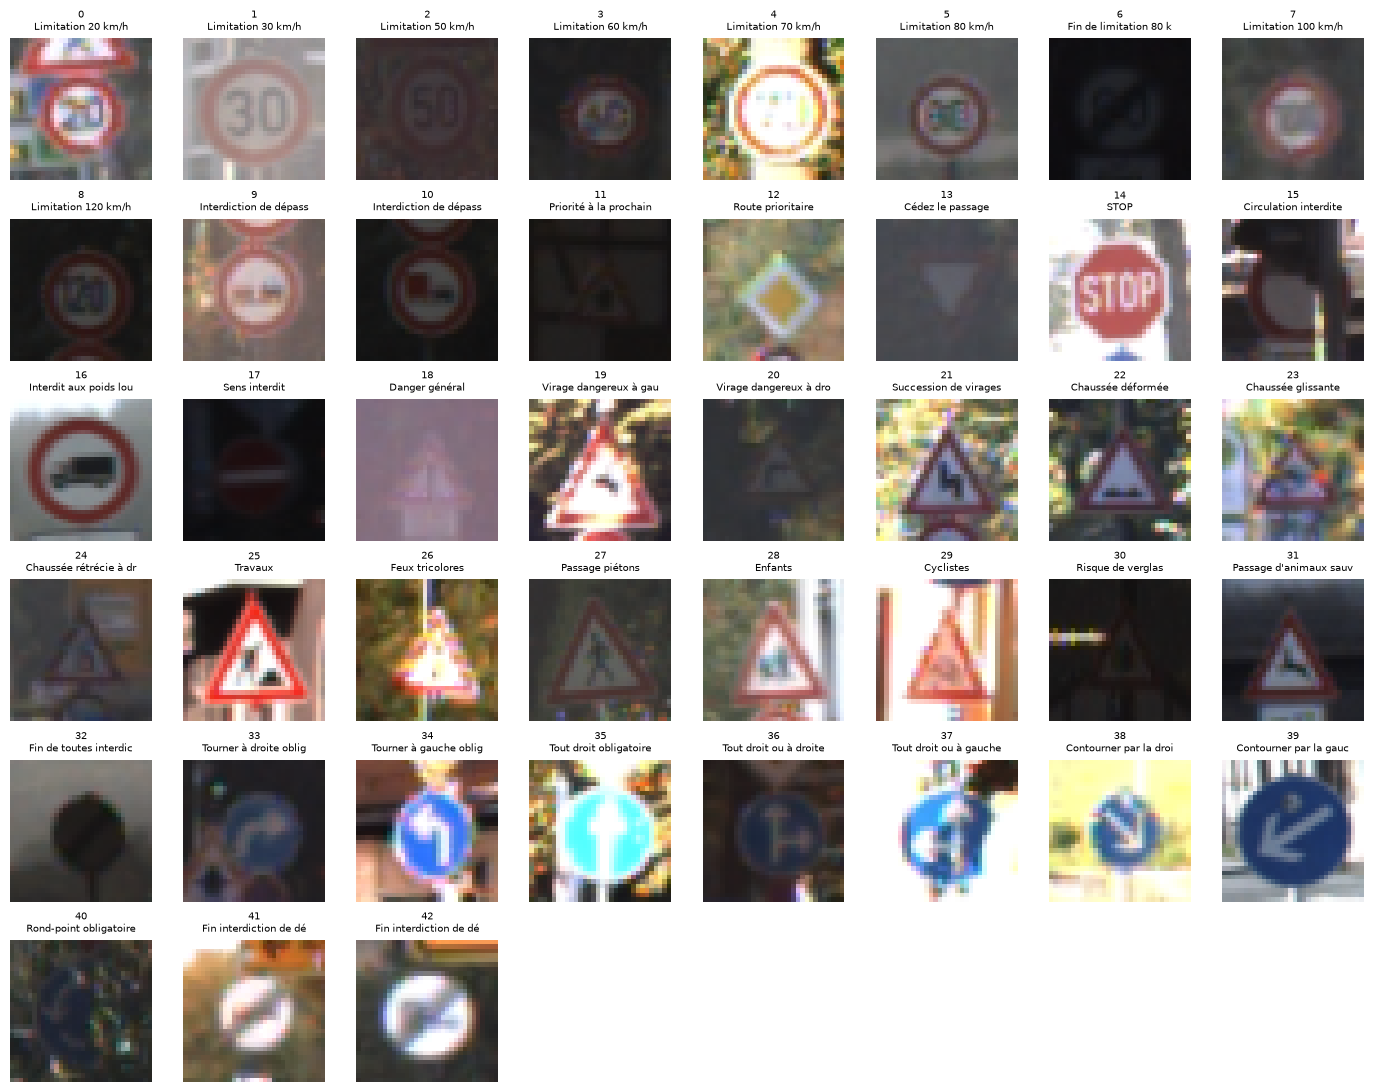

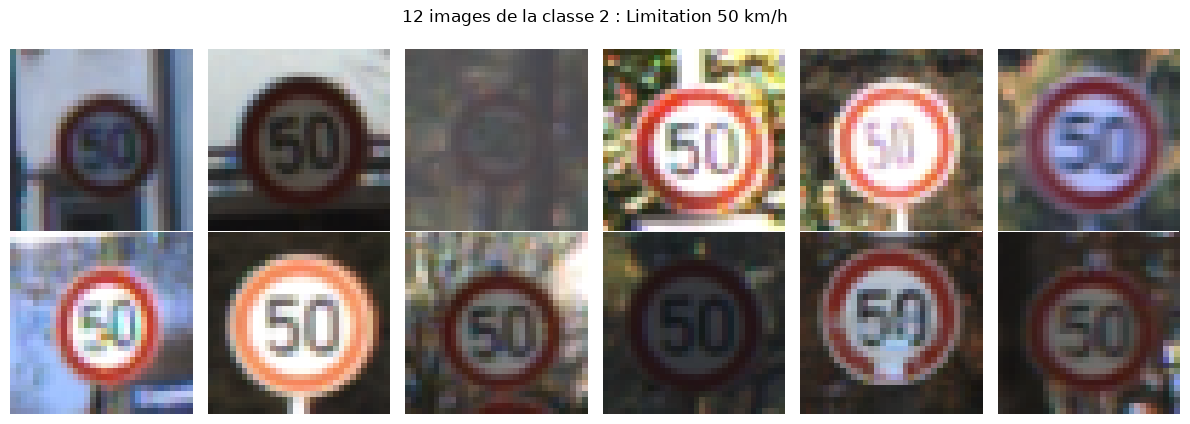

In [5]:
# Un exemple par classe
fig, axes = plt.subplots(6, 8, figsize=(14, 11))
for ax in axes.ravel():
    ax.axis("off")
for c in range(NUM_CLASSES):
    i = np.where(y_full == c)[0][0]
    axes.ravel()[c].imshow(X_full[i])
    axes.ravel()[c].set_title(f"{c}\n{CLASS_NAMES[c][:22]}", fontsize=7)
plt.tight_layout(); plt.show()

# Variabilité à l'intérieur d'une même classe (luminosité, flou, taille...)
CLASSE_A_VOIR = 2  # modifiez pour explorer
idx = np.random.RandomState(SEED).choice(np.where(y_full == CLASSE_A_VOIR)[0], 12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.3))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_full[i]); ax.axis("off")
fig.suptitle(f"12 images de la classe {CLASSE_A_VOIR} : {CLASS_NAMES[CLASSE_A_VOIR]}")
plt.tight_layout(); plt.show()

**Observations sur les données :**
- **Volume :** 39 270 images au total dans la version téléchargée : 26 640 pour l'entraînement et la validation, issues de **888 pistes**, et 12 630 pour le test.
- **Déséquilibre marqué :** les classes les plus fréquentes (limitations 30 et 50 km/h) ont **1 500 images**, les plus rares (limitation 20 km/h, virage dangereux à gauche, tout droit ou à gauche) seulement **150**, soit un **rapport de 10**. Une quinzaine de classes ont moins de 300 images ; ce sont surtout des panneaux de danger (cyclistes, passage piétons, chaussée rétrécie…) et des panneaux de « fin d'interdiction ». Le jeu de test suit exactement la même répartition.
- **Images petites et de qualité variable :** la taille d'origine va de **25 à 243 pixels**, avec une médiane de **43 px**. La moitié des panneaux font donc moins de 43×43 pixels avant redimensionnement, et le passage à 32×32 ne perd pas beaucoup d'information. Les exemples affichés montrent des images très sombres, d'autres surexposées, floues (mouvement du véhicule) ou décentrées.
- **Impact attendu sur l'apprentissage :** le modèle risque de favoriser les classes fréquentes et de moins bien reconnaître les classes rares. Les panneaux qui ne diffèrent que par un détail (les chiffres des limitations de vitesse, les pictogrammes des triangles de danger) devraient être les plus confondus, surtout lorsque l'image est petite ou sombre. Il faudra donc regarder la performance **par classe** (partie 5), pas seulement l'accuracy globale.

## 1.2 Préparation des données

| Étape | Rôle |
|---|---|
| **Redimensionnement** (32×32) | Un réseau dense ou convolutif + `Flatten` attend une taille d'entrée fixe ; les photos ont des tailles très différentes. 32×32 est un compromis calcul / information (les pictogrammes restent lisibles). |
| **Normalisation** (÷ 255) | Passe les pixels de [0, 255] à [0, 1] : entrées de même échelle, gradients mieux conditionnés, entraînement plus stable et plus rapide. |
| **Labels** | Classes numérotées 0…42 (entiers). Avec la loss `sparse_categorical_crossentropy`, Keras fait **en interne** l'équivalent de l'encodage one-hot : inutile de le construire à la main. |
| **Encodage one-hot** (illustration ci-dessous) | Représentation « un 1, des 0 » : vecteur de taille K qu'on compare à la sortie Softmax. Équivalent à `categorical_crossentropy`. |
| **Train / validation / test** | *Train* : apprendre les poids. *Validation* : régler hyperparamètres, détecter le surapprentissage, choisir le modèle. *Test* : mesure finale, **utilisé une seule fois**. |

Découpage obtenu : **21 300** images d'entraînement et **5 340** de validation (80 / 20, par piste ; les 43 classes sont présentes en validation), plus les **12 630** images de test.


In [6]:
# Découpage train / validation (80/20), stratifié et groupé par piste -> pas de fuite entre train et val
if groups_full is not None:
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    tr_idx, va_idx = next(sgkf.split(X_full, y_full, groups_full))
    assert not (set(groups_full[tr_idx]) & set(groups_full[va_idx])), "Fuite : une piste est des deux côtés"
else:
    print("Pistes indisponibles : découpage stratifié simple (validation un peu optimiste)")
    tr_idx, va_idx = train_test_split(np.arange(len(y_full)), test_size=0.2, stratify=y_full, random_state=SEED)

# Normalisation en float32 dans [0, 1]
X_train = X_full[tr_idx].astype("float32") / 255.0
X_val = X_full[va_idx].astype("float32") / 255.0
X_test = X_test_u8.astype("float32") / 255.0
y_train, y_val = y_full[tr_idx], y_full[va_idx]
sizes_val = sizes_full[va_idx]

print(f"Train : {X_train.shape}  labels {y_train.shape}")
print(f"Val   : {X_val.shape}  labels {y_val.shape}")
print(f"Test  : {X_test.shape}  labels {y_test.shape}   <- réservé à l'évaluation finale")
print(f"Pixels : min {X_train.min():.1f}, max {X_train.max():.1f}, dtype {X_train.dtype}")
print(f"Classes présentes en validation : {len(set(y_val))}/{NUM_CLASSES}")

# Illustration de l'encodage one-hot
print("\nLabel entier :", y_train[0], "->", CLASS_NAMES[y_train[0]])
print("One-hot      :", keras.utils.to_categorical(y_train[0], NUM_CLASSES).astype(int))

Train : (21300, 32, 32, 3)  labels (21300,)
Val   : (5340, 32, 32, 3)  labels (5340,)
Test  : (12630, 32, 32, 3)  labels (12630,)   <- réservé à l'évaluation finale
Pixels : min 0.0, max 1.0, dtype float32
Classes présentes en validation : 43/43

Label entier : 0 -> Limitation 20 km/h
One-hot      : [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0]


## Outils communs (fonctions réutilisées dans les parties suivantes)

In [7]:
RESULTS = []   # tableau comparatif des expériences
MODELS = {}    # modèles entraînés, par nom


def compile_and_fit(model, lr=1e-3, batch_size=64, epochs=20, callbacks=None, verbose=2):
    # Perte = entropie croisée pour labels entiers ; optimiseur = Adam ; métrique = accuracy
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    hist = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                     batch_size=batch_size, epochs=epochs, callbacks=callbacks, verbose=verbose)
    return hist, time.time() - t0


def plot_history(hist, title=""):
    hh = hist.history
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(hh["loss"], label="train"); ax[0].plot(hh["val_loss"], label="validation")
    ax[0].set_title("Loss"); ax[0].set_xlabel("Époque"); ax[0].legend()
    ax[1].plot(hh["accuracy"], label="train"); ax[1].plot(hh["val_accuracy"], label="validation")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("Époque"); ax[1].legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()


def log_result(name, change, hist, duration, model):
    hh = hist.history
    val_loss_final, val_acc_final = model.evaluate(X_val, y_val, verbose=0)
    RESULTS.append({
        "expérience": name,
        "modification": change,
        "paramètres": model.count_params(),
        "époques": len(hh["loss"]),
        "acc train (dernière)": round(hh["accuracy"][-1], 4),
        "acc val (max)": round(max(hh["val_accuracy"]), 4),
        "acc val (modèle conservé)": round(val_acc_final, 4),
        "loss val (modèle conservé)": round(val_loss_final, 4),
        "écart train - val": round(hh["accuracy"][-1] - hh["val_accuracy"][-1], 4),
        "temps (s)": round(duration),
    })
    MODELS[name] = model
    return pd.DataFrame(RESULTS)

# Partie 2 — Modèle de référence (réseau dense)

Architecture : `Image → Flatten → Dense(256, ReLU) → Dense(128, ReLU) → Dense(43, Softmax)`

Ce modèle sert de **point de comparaison** : il ignore la structure 2D de l'image (chaque pixel devient une entrée indépendante), ce que le CNN exploitera ensuite.

**Nombre de paramètres (confirmé par `summary()` ci-dessous) :**
- `Flatten` : 32×32×3 = **3 072** valeurs, 0 paramètre
- `Dense(256)` : 3 072 × 256 + 256 = **786 688**
- `Dense(128)` : 256 × 128 + 128 = **32 896**
- `Dense(43)` : 128 × 43 + 43 = **5 547**
- Total : **825 131**

Model: "baseline_dense"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 825,131 (3.15 MB)

 Trainable params: 825,131 (3.15 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
333/333 - 3s - 9ms/step - accuracy: 0.3967 - loss: 2.3764 - val_accuracy: 0.5150 - val_loss: 1.8290
Epoch 2/15
333/333 - 2s - 5ms/step - accuracy: 0.7035 - loss: 1.1092 - val_accuracy: 0.6809 - val_loss: 1.2972
Epoch 3/15
333/333 - 2s - 5ms/step - accuracy: 0.8186 - loss: 0.6991 - val_accuracy: 0.7204 - val_loss: 1.1435
Epoch 4/15
333/333 - 2s - 5ms/step - accuracy: 0.8628 - loss: 0.5348 - val_accuracy: 0.7393 - val_loss: 1.0751
Epoch 5/15
333/333 - 2s - 5ms/step - accuracy: 0.8801 - loss: 0.4575 - val_accuracy: 0.7721 - val_loss: 0.9896
Epoch 6/15
333/333 - 2s - 5ms/step - accuracy: 0.9030 - loss: 0.3700 - val_accuracy: 0.7682 - val_loss: 1.0150
Epoch 7/15
333/333 - 2s - 5ms/step - accuracy: 0.9141 - loss: 0.3235 - val_accuracy: 0.7801 - val_loss: 0.9907
Epoch 8/15
333/333 - 2s - 5ms/step - accuracy: 0.9164 - loss: 0.3229 - val_accuracy: 0.7809 - val_loss: 1.0078
Epoch 9/15
333/333 - 2s - 5ms/step - accuracy: 0.9254 - loss: 0.2802 - val_accuracy: 0.7904 - val_loss: 1.0528
E

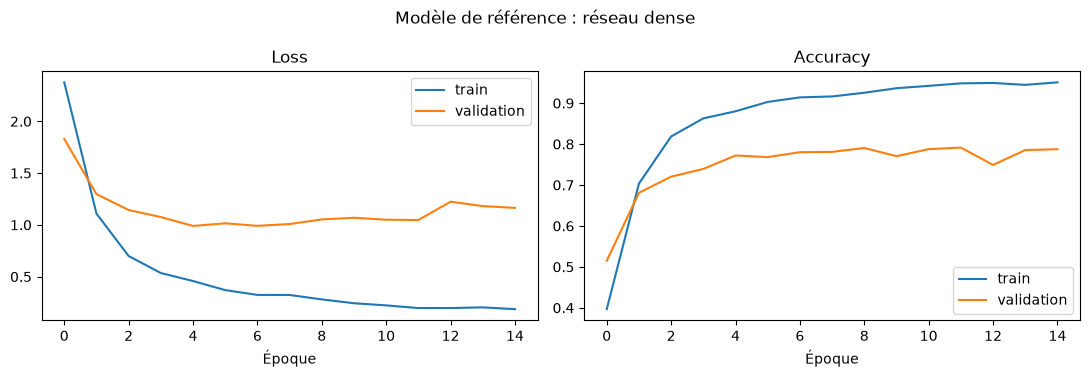

,expérience,modification,paramètres,époques,acc train (dernière),acc val (max),acc val (modèle conservé),loss val (modèle conservé),écart train - val,temps (s)
0,E0a - Dense,Flatten + Dense 256 + Dense 128 (référence),825131,15,0.9508,0.7914,0.7875,1.1641,0.1634,27


In [8]:
def build_dense(hidden=(256, 128), name="baseline_dense"):
    return keras.Sequential(
        [layers.Input(shape=(IMG, IMG, 3)), layers.Flatten()]
        + [layers.Dense(h, activation="relu") for h in hidden]
        + [layers.Dense(NUM_CLASSES, activation="softmax")],
        name=name)

keras.utils.set_random_seed(SEED)
dense = build_dense()
dense.summary()

hist_dense, t_dense = compile_and_fit(dense, lr=1e-3, batch_size=64, epochs=15)
plot_history(hist_dense, "Modèle de référence : réseau dense")
log_result("E0a - Dense", "Flatten + Dense 256 + Dense 128 (référence)", hist_dense, t_dense, dense)

## Explications — Partie 2

1. **Entrée du réseau.** Une image couleur est un tableau 32×32×3 : 32 lignes, 32 colonnes, 3 canaux (rouge, vert, bleu), chaque valeur étant normalisée dans [0, 1]. La couche `Flatten` met ces valeurs bout à bout en un vecteur de 32 × 32 × 3 = **3 072** nombres. On perd alors la **structure spatiale** : le réseau ne « sait » pas que deux pixels sont voisins. Un panneau décalé de quelques pixels produit un vecteur très différent, et le réseau doit réapprendre le même motif à chaque position.

2. **Poids et biais.** Chaque neurone de `Dense(256)` est relié aux 3 072 entrées par un **poids** (l'importance donnée à chaque pixel) et possède un **biais** (un décalage qui lui permet de s'activer même quand les entrées sont faibles). On a donc 3 072 × 256 poids + 256 biais = **786 688** paramètres. Ce sont ces valeurs que l'entraînement ajuste.

3. **Propagation avant.** Couche après couche, on calcule `z = W·x + b` (somme pondérée des entrées plus le biais), puis `a = f(z)` avec `f` la fonction d'activation. La sortie d'une couche devient l'entrée de la suivante, jusqu'aux 43 sorties.

4. **Fonctions d'activation.** Dans les couches cachées, on utilise **ReLU** : `ReLU(z) = max(0, z)`. Elle est simple à calculer, et son gradient vaut 1 pour z > 0, donc il ne s'écrase pas comme avec la sigmoïde (problème de *vanishing gradient*). **Sans activation non linéaire**, empiler des couches `Dense` reviendrait à une seule transformation linéaire : le réseau ne pourrait pas apprendre de frontières de décision complexes.

5. **Fonction de perte.** On utilise l'**entropie croisée** : `L = −ln(p_vraie classe)`. Si le réseau donne la probabilité 0,74 à la bonne classe, `L = −ln(0,74) ≈ 0,30`. S'il ne lui donne que 0,01, `L = −ln(0,01) ≈ 4,61`. La perte pénalise donc très fortement une prédiction fausse et sûre d'elle. La perte affichée est la moyenne sur le batch.

6. **Rétropropagation et descente de gradient.** La **rétropropagation** applique la règle de dérivation en chaîne de la sortie vers l'entrée, pour calculer `∂L/∂w` pour chaque poids, c'est-à-dire dans quelle direction et de combien chaque poids influence l'erreur. La **descente de gradient** met ensuite les poids à jour dans le sens qui diminue la perte : `w ← w − lr · ∂L/∂w`, où `lr` est le *learning rate* (taille du pas). On le fait par mini-batch de 64 images. **Adam** améliore cette règle : il garde une moyenne glissante des gradients (momentum) et adapte le pas de chaque paramètre selon l'amplitude de ses gradients passés.

7. **Sortie multiclasse.** La dernière couche a **43 neurones** (un par classe) suivis d'un **Softmax** : `p_i = e^{z_i} / Σ_j e^{z_j}`. On obtient 43 probabilités positives qui somment à 1. La classe prédite est celle de probabilité maximale (`argmax`). Pour un problème binaire, on aurait utilisé un seul neurone avec une sigmoïde.

# Partie 3 — Construction d'un CNN avec Keras

Architecture retenue :

`Image 32×32×3 → [Conv3×3 → ReLU] ×2 → MaxPool → [Conv ×2 → MaxPool] → [Conv ×2 → MaxPool] → Flatten → Dense(128, ReLU) → Dense(43, Softmax)`

avec 32, 64 puis 128 filtres. Le nombre de filtres double quand la résolution est divisée par 2 : on passe de motifs simples (bords, couleurs) à des motifs complexes (formes, chiffres, symboles).

## Évolution des dimensions et des paramètres

| Couche | Sortie | Paramètres | Calcul |
|---|---|---|---|
| Entrée | 32×32×3 | 0 | |
| Conv2D 32 (3×3, same) | 32×32×32 | 896 | 3·3·3·32 + 32 |
| Conv2D 32 (3×3, same) | 32×32×32 | 9 248 | 3·3·32·32 + 32 |
| MaxPooling 2×2 | 16×16×32 | 0 | |
| Conv2D 64 | 16×16×64 | 18 496 | 3·3·32·64 + 64 |
| Conv2D 64 | 16×16×64 | 36 928 | 3·3·64·64 + 64 |
| MaxPooling 2×2 | 8×8×64 | 0 | |
| Conv2D 128 | 8×8×128 | 73 856 | 3·3·64·128 + 128 |
| Conv2D 128 | 8×8×128 | 147 584 | 3·3·128·128 + 128 |
| MaxPooling 2×2 | 4×4×128 | 0 | |
| Flatten | 2 048 | 0 | 4·4·128 |
| Dense 128 + ReLU | 128 | 262 272 | 2048·128 + 128 |
| Dense 43 + Softmax | 43 | 5 547 | 128·43 + 43 |
| **Total** | | **554 827** | |

Un filtre 3×3 sur une image à 3 canaux a **3×3×3 = 27 poids** (un noyau 3×3 par canal, les trois résultats sont additionnés) **+ 1 biais** = 28 paramètres ; il produit **une** feature map. 32 filtres → 32 feature maps → 896 paramètres.

In [9]:
def build_cnn(filters=(32, 64, 128), dense_units=128, dropout=0.0, batchnorm=False,
              augment=False, name="cnn"):
    inputs = keras.Input(shape=(IMG, IMG, 3))
    x = inputs

    if augment:
        # Transformations qui CONSERVENT le sens du panneau. Pas de flip horizontal :
        # il transformerait "tourner à gauche" en "tourner à droite" (autre classe, même label).
        # Ces couches ne sont actives qu'à l'entraînement (pas à la validation / au test).
        x = keras.Sequential([
            layers.RandomRotation(0.03, fill_mode="nearest"),            # ~ +/- 11 degrés
            layers.RandomZoom(0.10, fill_mode="nearest"),
            layers.RandomTranslation(0.08, 0.08, fill_mode="nearest"),
            layers.RandomBrightness(0.2, value_range=(0, 1)),
            layers.RandomContrast(0.2),
        ], name="data_augmentation")(x)

    for f in filters:
        for _ in range(2):
            x = layers.Conv2D(f, 3, padding="same")(x)
            if batchnorm:
                x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D(2)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name)


keras.utils.set_random_seed(SEED)
cnn = build_cnn(name="cnn_base")
cnn.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 554,827 (2.12 MB)

 Trainable params: 554,827 (2.12 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Vérification du nombre de paramètres par le calcul
def conv_params(k, c_in, c_out):
    return k * k * c_in * c_out + c_out

def dense_params(n_in, n_out):
    return n_in * n_out + n_out

manual = (conv_params(3, 3, 32) + conv_params(3, 32, 32)
          + conv_params(3, 32, 64) + conv_params(3, 64, 64)
          + conv_params(3, 64, 128) + conv_params(3, 128, 128)
          + dense_params(4 * 4 * 128, 128) + dense_params(128, NUM_CLASSES))
print("Paramètres calculés à la main :", manual)
print("Paramètres Keras              :", cnn.count_params())
assert manual == cnn.count_params()

Paramètres calculés à la main : 554827
Paramètres Keras              : 554827


## Justification et explications — Partie 3

- **Filtres et feature maps.** Un filtre est un petit tableau de poids (ici 3×3×canaux) qui glisse sur l'image et répond fortement là où il retrouve « son » motif. Chaque filtre produit une **feature map** : une carte indiquant où ce motif est présent. Dans les **premières couches**, les filtres détectent des motifs simples : bords, contrastes, couleurs (rouge du contour, bleu des panneaux d'obligation). Dans les **dernières couches**, ils combinent ces motifs en formes plus complexes : cercle, triangle, chiffres, flèches, pictogrammes.

- **Convolution sur 3 canaux.** Un filtre 3×3 appliqué à une image RGB a en réalité une profondeur de 3 : un noyau 3×3 par canal, soit **27 poids + 1 biais**. À chaque position, on multiplie terme à terme les 27 valeurs de l'image par les 27 poids, on additionne le tout, on ajoute le biais : on obtient **une** valeur de la feature map. Dans les couches suivantes, la profondeur du filtre est égale au nombre de feature maps en entrée (32, puis 64…).

- **Taille du kernel (3×3).** C'est le plus petit noyau qui capte un voisinage centré. Deux convolutions 3×3 empilées voient une zone de 5×5 pixels (comme un 5×5) avec moins de paramètres (2 × 9 = 18 poids par canal au lieu de 25) et une non-linéarité ReLU en plus, donc une représentation plus riche.

- **Stride.** C'est le pas de déplacement du filtre. Il vaut 1 pour nos convolutions (on garde toute la résolution) et 2 pour le MaxPooling 2×2 (la taille est divisée par 2). Formule : `sortie = (entrée + 2·padding − kernel) / stride + 1`.

- **Padding.** Avec `padding="same"`, on ajoute une bordure de zéros pour que la sortie garde la même taille que l'entrée (32×32 → 32×32). Avec `valid`, chaque convolution 3×3 ferait perdre 2 pixels. Sur des images de 32×32, on conserve ainsi l'information des bords, et la réduction de taille est contrôlée uniquement par le pooling.

- **ReLU.** `max(0, z)` après chaque convolution : met à zéro les réponses négatives, introduit la non-linéarité et garde des gradients stables.

- **Pooling.** Le `MaxPooling 2×2` garde la valeur maximale de chaque bloc de 2×2. Il divise la résolution par 2 (32 → 16 → 8 → 4), ce qui réduit les calculs et les paramètres de la partie dense. Il rend aussi le réseau un peu tolérant aux petits décalages : peu importe la position exacte du motif dans le bloc.

- **Flatten, Dense et sortie.** La carte finale 4×4×128 est aplatie en un vecteur de **2 048** caractéristiques. `Dense(128, ReLU)` combine ces caractéristiques, puis `Dense(43, Softmax)` donne une probabilité pour chacune des 43 classes.

- **Nos choix d'architecture.**
  - **3 blocs :** partant de 32×32, trois poolings mènent à 4×4. Un quatrième bloc donnerait 2×2, ce qui laisse trop peu d'information spatiale.
  - **32 → 64 → 128 filtres :** on double le nombre de filtres quand la résolution est divisée par 2. Le coût de calcul reste à peu près constant d'un bloc à l'autre, et il faut plus de filtres pour représenter des motifs plus complexes que pour des bords simples.
  - **Deux convolutions par bloc :** cela augmente le champ réceptif avant chaque pooling.
  - **`Dense(128)` :** c'est suffisant pour combiner les caractéristiques extraites vers 43 classes. Cette couche contient déjà la moitié des paramètres du réseau (262 272) ; la prendre plus grande favoriserait le surapprentissage.
  - **Comparaison avec le réseau dense :** le CNN a **moins de paramètres** que lui (554 827 contre 825 131), car les poids d'un filtre sont **partagés** sur toute l'image.

# Partie 4 — Entraînement du réseau

| Choix | Valeur | Justification |
|---|---|---|
| Fonction de perte | `sparse_categorical_crossentropy` | Classification multiclasse, labels entiers, sortie Softmax |
| Optimiseur | Adam, lr = 1e-3 | Learning rate adaptatif par paramètre, valeur par défaut robuste |
| Batch size | 64 | Compromis stabilité du gradient / vitesse / mémoire GPU |
| Époques | 20 | Assez pour observer la convergence **et** un éventuel surapprentissage (volontairement sans Early Stopping ici) |
| Métrique | accuracy | Simple à lire ; complétée en partie 5 par matrice de confusion et F1 par classe |

Epoch 1/20
333/333 - 18s - 53ms/step - accuracy: 0.3423 - loss: 2.3039 - val_accuracy: 0.6056 - val_loss: 1.3602
Epoch 2/20
333/333 - 15s - 46ms/step - accuracy: 0.8687 - loss: 0.4110 - val_accuracy: 0.8039 - val_loss: 0.7664
Epoch 3/20
333/333 - 15s - 45ms/step - accuracy: 0.9639 - loss: 0.1217 - val_accuracy: 0.8721 - val_loss: 0.5527
Epoch 4/20
333/333 - 14s - 42ms/step - accuracy: 0.9835 - loss: 0.0520 - val_accuracy: 0.8831 - val_loss: 0.5729
Epoch 5/20
333/333 - 14s - 41ms/step - accuracy: 0.9883 - loss: 0.0380 - val_accuracy: 0.8886 - val_loss: 0.5116
Epoch 6/20
333/333 - 15s - 47ms/step - accuracy: 0.9887 - loss: 0.0362 - val_accuracy: 0.8882 - val_loss: 0.5166
Epoch 7/20
333/333 - 17s - 51ms/step - accuracy: 0.9914 - loss: 0.0268 - val_accuracy: 0.8944 - val_loss: 0.4793
Epoch 8/20
333/333 - 18s - 53ms/step - accuracy: 0.9941 - loss: 0.0180 - val_accuracy: 0.8770 - val_loss: 0.6239
Epoch 9/20
333/333 - 16s - 49ms/step - accuracy: 0.9947 - loss: 0.0198 - val_accuracy: 0.9110 - 

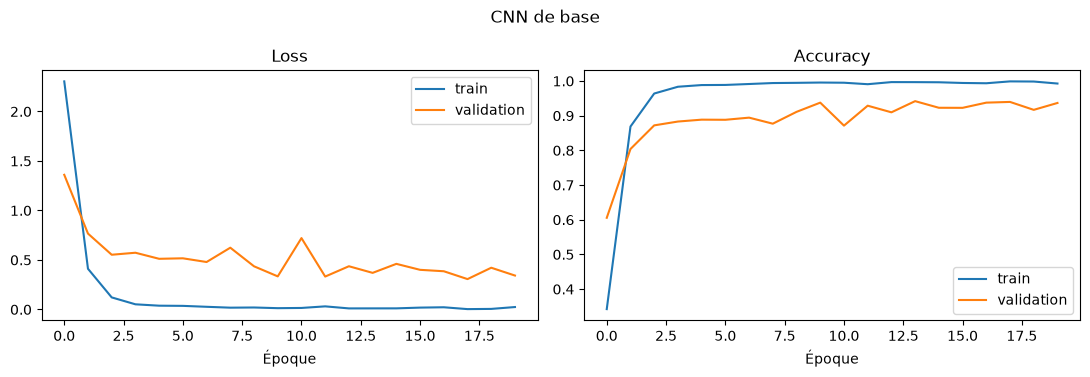

,expérience,modification,paramètres,époques,acc train (dernière),acc val (max),acc val (modèle conservé),loss val (modèle conservé),écart train - val,temps (s)
0,E0a - Dense,Flatten + Dense 256 + Dense 128 (référence),825131,15,0.9508,0.7914,0.7875,1.1641,0.1634,27
1,E0b - CNN de base,"3 blocs conv (32-64-128), Dense 128, Adam 1e-3...",554827,20,0.9927,0.9419,0.9367,0.3425,0.0560,284


In [11]:
keras.utils.set_random_seed(SEED)
cnn = build_cnn(name="cnn_base")
hist_cnn, t_cnn = compile_and_fit(cnn, lr=1e-3, batch_size=64, epochs=20)
plot_history(hist_cnn, "CNN de base")
log_result("E0b - CNN de base", "3 blocs conv (32-64-128), Dense 128, Adam 1e-3, batch 64", hist_cnn, t_cnn, cnn)

**Interprétation des courbes**

| Modèle | Acc train (fin) | Acc val (fin) | Écart | Meilleure val_loss |
|---|---|---|---|---|
| Dense (partie 2) | 95,1 % | 78,8 % | 16,3 pts | 0,99 à l'époque 5, puis remonte à 1,16 |
| CNN de base | 99,3 % | 93,7 % | 5,6 pts | 0,31 à l'époque 18, avec de fortes oscillations entre 0,31 et 0,72 |

- **Convergence.** La loss d'entraînement du CNN chute très vite : l'accuracy d'entraînement dépasse 96 % dès l'époque 3 et approche 100 % ensuite, avec une loss proche de 0,01. La loss de validation baisse jusqu'à l'époque 10 environ (0,33), puis **ne progresse plus vraiment**. Elle oscille fortement d'une époque à l'autre : 0,72 à l'époque 11, 0,31 à l'époque 18. L'accuracy de validation varie entre 87 % et 94 %.
- **Surapprentissage.** Il est net :
  - le réseau a pratiquement mémorisé l'ensemble d'entraînement (≈ 99-100 %), alors qu'il plafonne vers 93-94 % en validation ;
  - la val_loss (~0,35) reste environ **30 fois plus grande** que la train_loss (~0,01).

  Les oscillations montrent aussi que le modèle est très sûr de lui sur certaines images de validation qu'il classe mal : une seule piste mal reconnue (30 images d'un même panneau) suffit à faire bouger les scores. Comme le découpage est fait par piste, la validation contient des panneaux physiques jamais vus, ce qui rend ce surapprentissage bien visible. C'est ce qui motive la partie 6 (Dropout, Data Augmentation, BatchNorm, Early Stopping).
- **Le réseau dense surapprend encore plus.** Sa val_loss est minimale dès l'époque 5 puis remonte, alors que la train_loss continue de baisser, et l'écart final atteint 16 points.
- **Comparaison des deux modèles.** Le CNN gagne **+14,9 points** en validation (93,7 % contre 78,8 %) avec **33 % de paramètres en moins** (554 827 contre 825 131). Le gain vient de la convolution : les poids d'un filtre sont partagés sur toute l'image, le réseau exploite le voisinage des pixels et reconnaît un motif où qu'il soit dans l'image. Le CNN est en revanche environ 10 fois plus long à entraîner sur CPU (284 s contre 27 s).


# Partie 5 — Évaluation et analyse des erreurs

> Les analyses ci-dessous sont faites sur la **validation**, pour ne pas toucher au jeu de test. Les mêmes fonctions seront relancées **une seule fois sur le test** à la fin de la partie 6, avec le modèle final choisi.

[validation] accuracy = 0.9367 | F1 macro = 0.8942


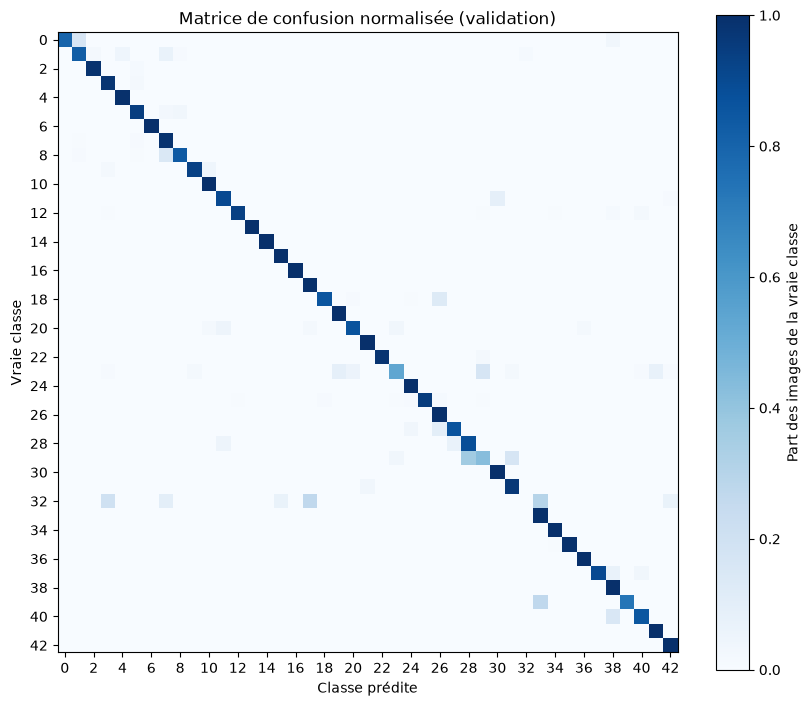


Classes les plus difficiles (recall le plus bas) :


,classe,support,recall,précision
32,32 - Fin de toutes interdictions,30,0.000,0.000
29,29 - Cyclistes,30,0.433,0.406
23,23 - Chaussée glissante,90,0.533,0.923
39,39 - Contourner par la gauche,30,0.733,1.000
0,0 - Limitation 20 km/h,30,0.800,0.923
1,1 - Limitation 30 km/h,300,0.827,0.969
8,8 - Limitation 120 km/h,210,0.838,0.941
40,40 - Rond-point obligatoire,60,0.850,0.879


Paires de classes les plus confondues :


,vraie classe,prédite,nb erreurs
0,8 - Limitation 120 km/h,7 - Limitation 100 km/h,31
1,18 - Danger général,26 - Feux tricolores,23
2,1 - Limitation 30 km/h,7 - Limitation 100 km/h,21
3,11 - Priorité à la prochaine intersection,30 - Risque de verglas,16
4,23 - Chaussée glissante,29 - Cyclistes,15
5,1 - Limitation 30 km/h,4 - Limitation 70 km/h,14
6,29 - Cyclistes,28 - Enfants,11
7,40 - Rond-point obligatoire,38 - Contourner par la droite,9
8,32 - Fin de toutes interdictions,33 - Tourner à droite obligatoire,9
9,23 - Chaussée glissante,19 - Virage dangereux à gauche,8


Taux d'erreur par quartile de luminosité :


,taux d'erreur
niveau de luminosité,
très sombre,0.0637
sombre,0.0712
clair,0.0464
très clair,0.0719


Taux d'erreur par quartile de taille d'origine du panneau :


,taux d'erreur
taille d'origine,
"(24.999, 34.0]",0.0980
"(34.0, 41.0]",0.0528
"(41.0, 56.0]",0.0396
"(56.0, 205.0]",0.0567


Taux d'erreur par quartile de netteté (variance du Laplacien) :


,taux d'erreur
niveau de netteté,
très flou,0.0772
flou,0.0644
net,0.0742
très net,0.0375


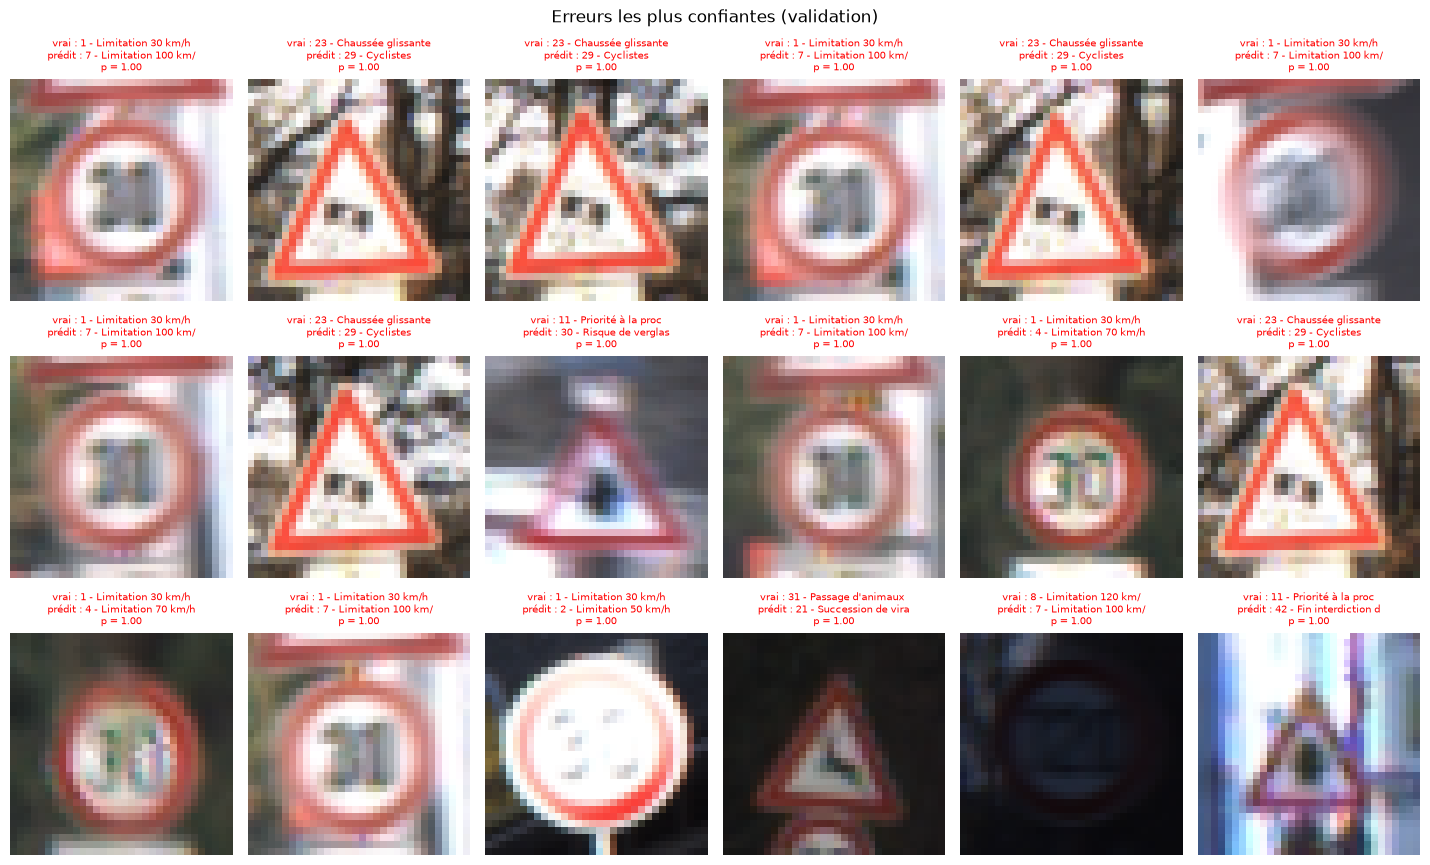

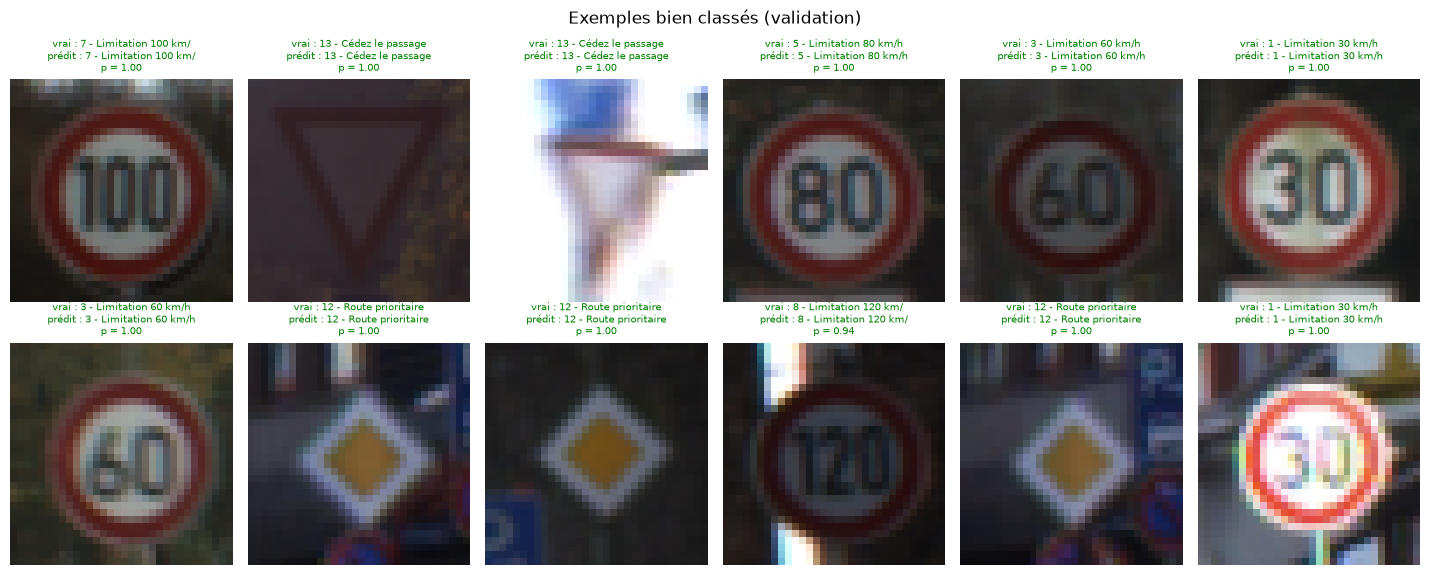

In [12]:
def show_predictions(X, y, pred, probs, idx, title, ncols=6):
    idx = list(idx)[: ncols * 3]
    if len(idx) == 0:
        print("Rien à afficher."); return
    nrows = int(np.ceil(len(idx) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.4 * ncols, 3.0 * nrows))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), idx):
        ok = pred[i] == y[i]
        ax.imshow(X[i])
        ax.set_title(f"vrai : {y[i]} - {CLASS_NAMES[y[i]][:18]}\n"
                     f"prédit : {pred[i]} - {CLASS_NAMES[pred[i]][:18]}\n"
                     f"p = {probs[i, pred[i]]:.2f}",
                     fontsize=7, color="green" if ok else "red")
    fig.suptitle(title); plt.tight_layout(); plt.show()


def sharpness(X):
    # Netteté = variance du Laplacien de l'image en niveaux de gris : faible -> image floue
    g = X.mean(axis=3)
    lap = (4 * g[:, 1:-1, 1:-1] - g[:, :-2, 1:-1] - g[:, 2:, 1:-1] - g[:, 1:-1, :-2] - g[:, 1:-1, 2:])
    return lap.var(axis=(1, 2))


def analyze(model, X, y, sizes, split_name="validation"):
    probs = model.predict(X, batch_size=256, verbose=0)
    pred = probs.argmax(axis=1)
    ok = pred == y
    print(f"[{split_name}] accuracy = {ok.mean():.4f} | F1 macro = {f1_score(y, pred, average='macro'):.4f}")

    # --- Matrice de confusion (normalisée par ligne : part de chaque vraie classe)
    cm = confusion_matrix(y, pred, labels=range(NUM_CLASSES))
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    plt.figure(figsize=(10, 8.5))
    plt.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    plt.colorbar(label="Part des images de la vraie classe")
    plt.xlabel("Classe prédite"); plt.ylabel("Vraie classe")
    plt.title(f"Matrice de confusion normalisée ({split_name})")
    plt.xticks(range(0, NUM_CLASSES, 2)); plt.yticks(range(0, NUM_CLASSES, 2))
    plt.show()

    # --- Performances par classe
    per_class = pd.DataFrame({
        "classe": [f"{i} - {CLASS_NAMES[i]}" for i in range(NUM_CLASSES)],
        "support": cm.sum(axis=1),
        "recall": np.diag(cm) / np.maximum(cm.sum(axis=1), 1),
        "précision": np.diag(cm) / np.maximum(cm.sum(axis=0), 1),
    })
    print("\nClasses les plus difficiles (recall le plus bas) :")
    display(per_class.sort_values("recall").head(8).round(3))

    # --- Confusions les plus fréquentes
    off = cm.copy(); np.fill_diagonal(off, 0)
    rows = []
    for flat in np.argsort(off, axis=None)[::-1][:10]:
        t, p = np.unravel_index(flat, off.shape)
        if off[t, p] == 0:
            break
        rows.append({"vraie classe": f"{t} - {CLASS_NAMES[t]}", "prédite": f"{p} - {CLASS_NAMES[p]}",
                     "nb erreurs": int(off[t, p])})
    print("Paires de classes les plus confondues :")
    display(pd.DataFrame(rows))

    # --- Erreurs vs luminosité, taille d'origine et flou
    df = pd.DataFrame({"correct": ok,
                       "luminosité": X.mean(axis=(1, 2, 3)),
                       "taille d'origine (px)": sizes.min(axis=1),
                       "netteté": sharpness(X)})
    df["niveau de luminosité"] = pd.qcut(df["luminosité"], 4, labels=["très sombre", "sombre", "clair", "très clair"])
    df["taille d'origine"] = pd.qcut(df["taille d'origine (px)"], 4, duplicates="drop")
    df["niveau de netteté"] = pd.qcut(df["netteté"], 4, labels=["très flou", "flou", "net", "très net"])
    print("Taux d'erreur par quartile de luminosité :")
    display((1 - df.groupby("niveau de luminosité", observed=True)["correct"].mean()).round(4).to_frame("taux d'erreur"))
    print("Taux d'erreur par quartile de taille d'origine du panneau :")
    display((1 - df.groupby("taille d'origine", observed=True)["correct"].mean()).round(4).to_frame("taux d'erreur"))
    print("Taux d'erreur par quartile de netteté (variance du Laplacien) :")
    display((1 - df.groupby("niveau de netteté", observed=True)["correct"].mean()).round(4).to_frame("taux d'erreur"))

    # --- Exemples : erreurs les plus confiantes, puis réussites
    wrong = np.where(~ok)[0]
    wrong = wrong[np.argsort(-probs[wrong, pred[wrong]])]
    show_predictions(X, y, pred, probs, wrong, f"Erreurs les plus confiantes ({split_name})")
    right = np.random.RandomState(SEED).choice(np.where(ok)[0], min(12, ok.sum()), replace=False)
    show_predictions(X, y, pred, probs, right, f"Exemples bien classés ({split_name})")
    return probs, pred, cm


probs_val, pred_val, cm_val = analyze(cnn, X_val, y_val, sizes_val, "validation")

**Analyse des erreurs (CNN de base, validation : accuracy 93,7 %, F1 macro 0,894)**

- **Accuracy et F1 macro.** Le F1 macro (0,894) est nettement plus bas que l'accuracy (0,937) : une moyenne qui donne le même poids à chaque classe fait apparaître les classes mal reconnues que l'accuracy globale masque. La matrice de confusion montre une diagonale très marquée : la grande majorité des 43 classes ont un recall supérieur à 90 %.

- **Panneaux bien reconnus.** Ce sont ceux dont la forme ou la couleur est unique : STOP, cédez le passage, route prioritaire, panneaux d'obligation bleus. Aucun d'eux n'apparaît parmi les classes difficiles.

- **Confusions les plus fréquentes.**
  - **Limitations de vitesse entre elles :** 120 → 100 km/h (31 erreurs), 30 → 100 km/h (21), 30 → 70 km/h (14). Même disque rouge, seuls les chiffres diffèrent, et à 32×32 un chiffre ne fait que quelques pixels. Le « 1 » ajouté devant « 20 » ou le « 3 » à la place du « 7 » se perdent facilement.
  - **Triangles de danger entre eux :** danger général → feux tricolores (23), priorité à la prochaine intersection → risque de verglas (16), chaussée glissante → cyclistes (15), cyclistes → enfants (11). Même triangle rouge, pictogramme central minuscule et souvent noir sur fond sombre.

- **Classes difficiles.**

  | Classe | Recall | Nombre d'images (train+val) |
  |---|---|---|
  | Fin de toutes interdictions | 0 % | 180 |
  | Cyclistes | 43 % | 180 |
  | Chaussée glissante | 53 % | 360 |
  | Contourner par la gauche | 73 % | 210 |
  | Limitation 20 km/h | 80 % | 150 |

  Ce sont presque toutes des **classes rares** : le déséquilibre explique une bonne partie des erreurs, car le réseau a peu d'exemples pour apprendre ces pictogrammes et il penche vers une classe voisine plus fréquente.
  - **Attention à la taille de l'échantillon :** pour une classe rare, la validation ne contient que **30 images, soit une seule piste**. Un recall de 0 % signifie donc qu'un seul panneau physique, photographié 30 fois, a été mal reconnu ; ici « fin de toutes interdictions » est confondu avec « tourner à droite obligatoire » (9 erreurs). Ces recalls par classe sont très bruités, d'où l'intérêt de regarder aussi le test (12 630 images).
  - **Limitation 30 km/h :** c'est une classe très fréquente avec un recall de seulement 83 %. Ici, la **ressemblance** avec les autres limitations est la cause principale.

- **Taille, flou et luminosité.**
  - **Taille :** c'est l'effet le plus net. Le taux d'erreur atteint **9,8 %** pour le quart des panneaux les plus petits (≤ 34 px à l'origine), contre 4 à 6 % pour les autres.
  - **Flou :** les images les plus nettes ont le taux d'erreur le plus bas (**3,8 %**, contre 6,4 à 7,7 % pour les autres quartiles).
  - **Luminosité :** pas de tendance claire. Les erreurs vont de 4,6 % à 7,2 % et sont plutôt plus fréquentes aux deux extrêmes (très sombre 6,4 %, très clair 7,2 %).
  - **Angle de vue :** il n'est pas mesuré automatiquement. Les erreurs les plus confiantes affichées montrent surtout des panneaux sombres ou surexposés, flous, partiellement masqués ou vus de biais.

- **Pourquoi l'accuracy seule ne suffit pas.** Avec des classes déséquilibrées, un modèle peut avoir une accuracy globale élevée (93,7 %) tout en ne reconnaissant jamais une classe rare (0 % pour « fin de toutes interdictions »). Une classe de 30 images ne pèse que 0,6 % de la validation. C'est pour cela qu'on regarde la **matrice de confusion**, le **recall par classe** et le **F1 macro**.


# Partie 6 — Expérimentation et amélioration

Chaque expérience modifie **un seul élément** par rapport au CNN de base (E0b) pour que l'effet soit interprétable. On compare tout sur la **validation**.

| Expérience | Modification | Hypothèse |
|---|---|---|
| E1 | Dropout 0,5 avant la couche de sortie | Réduit le surapprentissage |
| E2 | Data Augmentation (rotation, zoom, translation, luminosité, contraste ; **pas de flip**) | Plus de variété, meilleure généralisation (images sombres, décentrées) |
| E3 | Batch Normalization après chaque convolution | Entraînement plus stable et plus rapide |
| E4 | Combinaison des modifications utiles + Early Stopping + plus d'époques | Meilleur modèle final |

> **Point d'attention — Data Augmentation :** un retournement horizontal change le sens de certains panneaux (gauche ↔ droite) sans changer le label : on l'exclut. Les transformations retenues conservent le sens du panneau.

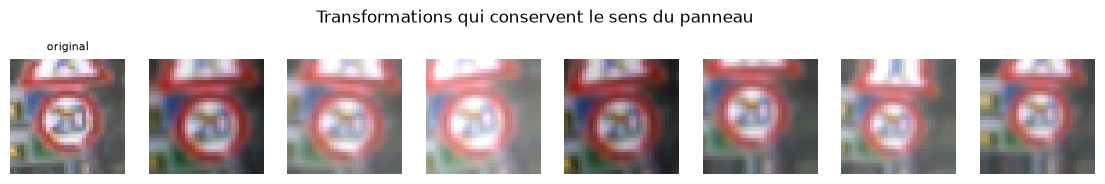

In [13]:
# Aperçu de la Data Augmentation sur une même image
aug_model = build_cnn(augment=True, name="apercu_aug")
aug_layer = aug_model.get_layer("data_augmentation")
sample = X_train[:1]
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
axes[0].imshow(sample[0]); axes[0].set_title("original", fontsize=8)
for ax in axes[1:]:
    ax.imshow(np.clip(aug_layer(sample, training=True)[0].numpy(), 0, 1))
for ax in axes:
    ax.axis("off")
plt.suptitle("Transformations qui conservent le sens du panneau"); plt.show()

Epoch 1/20
333/333 - 17s - 51ms/step - accuracy: 0.2550 - loss: 2.6369 - val_accuracy: 0.4116 - val_loss: 1.7837
Epoch 2/20
333/333 - 14s - 42ms/step - accuracy: 0.5901 - loss: 1.2446 - val_accuracy: 0.7764 - val_loss: 0.7451
Epoch 3/20
333/333 - 13s - 40ms/step - accuracy: 0.8388 - loss: 0.4849 - val_accuracy: 0.8747 - val_loss: 0.4182
Epoch 4/20
333/333 - 13s - 40ms/step - accuracy: 0.9229 - loss: 0.2436 - val_accuracy: 0.9079 - val_loss: 0.3266
Epoch 5/20
333/333 - 15s - 46ms/step - accuracy: 0.9529 - loss: 0.1477 - val_accuracy: 0.9346 - val_loss: 0.2594
Epoch 6/20
333/333 - 13s - 40ms/step - accuracy: 0.9679 - loss: 0.1037 - val_accuracy: 0.9433 - val_loss: 0.2728
Epoch 7/20
333/333 - 13s - 38ms/step - accuracy: 0.9763 - loss: 0.0779 - val_accuracy: 0.9406 - val_loss: 0.2611
Epoch 8/20
333/333 - 12s - 37ms/step - accuracy: 0.9820 - loss: 0.0622 - val_accuracy: 0.9468 - val_loss: 0.2030
Epoch 9/20
333/333 - 12s - 37ms/step - accuracy: 0.9813 - loss: 0.0611 - val_accuracy: 0.9365 - 

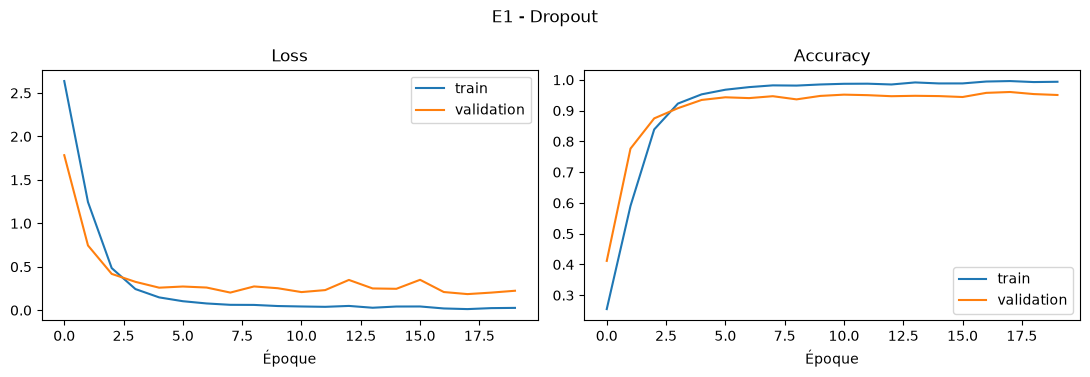

Epoch 1/20
333/333 - 15s - 44ms/step - accuracy: 0.3037 - loss: 2.4237 - val_accuracy: 0.4657 - val_loss: 1.6318
Epoch 2/20
333/333 - 13s - 40ms/step - accuracy: 0.6458 - loss: 1.0996 - val_accuracy: 0.7436 - val_loss: 0.8319
Epoch 3/20
333/333 - 13s - 40ms/step - accuracy: 0.8574 - loss: 0.4487 - val_accuracy: 0.8215 - val_loss: 0.6203
Epoch 4/20
333/333 - 13s - 39ms/step - accuracy: 0.9197 - loss: 0.2624 - val_accuracy: 0.8669 - val_loss: 0.5697
Epoch 5/20
333/333 - 13s - 40ms/step - accuracy: 0.9470 - loss: 0.1800 - val_accuracy: 0.8904 - val_loss: 0.3989
Epoch 6/20
333/333 - 13s - 40ms/step - accuracy: 0.9552 - loss: 0.1497 - val_accuracy: 0.8846 - val_loss: 0.4915
Epoch 7/20
333/333 - 13s - 38ms/step - accuracy: 0.9608 - loss: 0.1290 - val_accuracy: 0.9058 - val_loss: 0.4377
Epoch 8/20
333/333 - 13s - 39ms/step - accuracy: 0.9669 - loss: 0.1110 - val_accuracy: 0.9189 - val_loss: 0.4145
Epoch 9/20
333/333 - 13s - 39ms/step - accuracy: 0.9721 - loss: 0.0944 - val_accuracy: 0.8993 - 

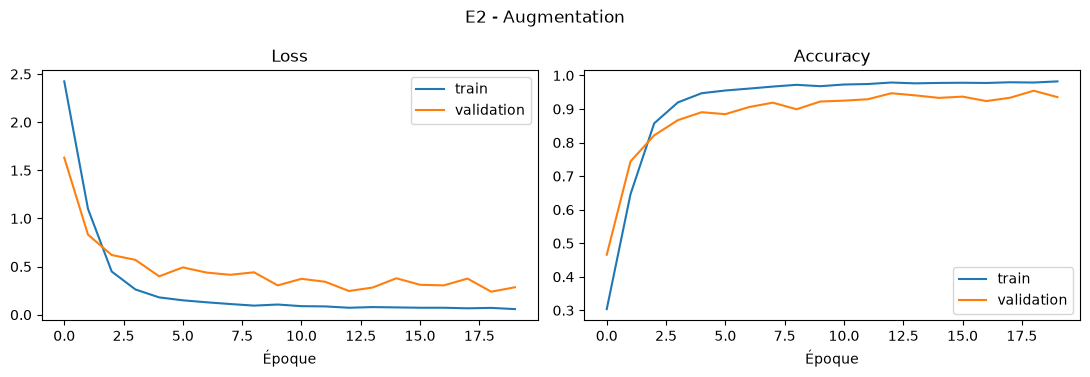

Epoch 1/20
333/333 - 22s - 65ms/step - accuracy: 0.7860 - loss: 0.8153 - val_accuracy: 0.7805 - val_loss: 0.7567
Epoch 2/20
333/333 - 20s - 59ms/step - accuracy: 0.9958 - loss: 0.0231 - val_accuracy: 0.9187 - val_loss: 0.2956
Epoch 3/20
333/333 - 23s - 69ms/step - accuracy: 0.9981 - loss: 0.0095 - val_accuracy: 0.9502 - val_loss: 0.1740
Epoch 4/20
333/333 - 21s - 62ms/step - accuracy: 0.9965 - loss: 0.0135 - val_accuracy: 0.8837 - val_loss: 0.5441
Epoch 5/20
333/333 - 20s - 60ms/step - accuracy: 0.9942 - loss: 0.0211 - val_accuracy: 0.9303 - val_loss: 0.2494
Epoch 6/20
333/333 - 21s - 64ms/step - accuracy: 0.9933 - loss: 0.0224 - val_accuracy: 0.9575 - val_loss: 0.1660
Epoch 7/20
333/333 - 23s - 71ms/step - accuracy: 0.9949 - loss: 0.0173 - val_accuracy: 0.9412 - val_loss: 0.2118
Epoch 8/20
333/333 - 23s - 68ms/step - accuracy: 0.9981 - loss: 0.0059 - val_accuracy: 0.9743 - val_loss: 0.0909
Epoch 9/20
333/333 - 21s - 64ms/step - accuracy: 1.0000 - loss: 1.8773e-04 - val_accuracy: 0.981

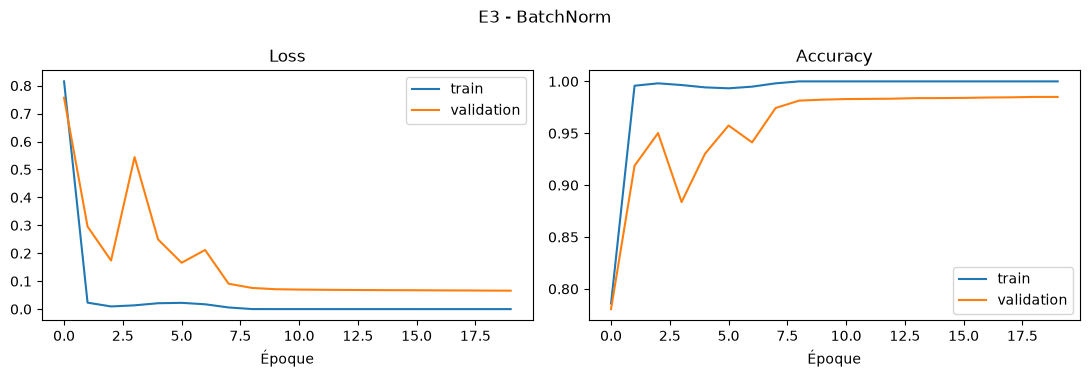

,expérience,modification,paramètres,époques,acc train (dernière),acc val (max),acc val (modèle conservé),loss val (modèle conservé),écart train - val,temps (s)
0,E0a - Dense,Flatten + Dense 256 + Dense 128 (référence),825131,15,0.9508,0.7914,0.7875,1.1641,0.1634,27
1,E0b - CNN de base,"3 blocs conv (32-64-128), Dense 128, Adam 1e-3...",554827,20,0.9927,0.9419,0.9367,0.3425,0.0560,284
2,E1 - Dropout,"Dropout 0,5 avant la sortie",554827,20,0.9937,0.9605,0.9507,0.2240,0.0430,260
3,E2 - Augmentation,Data Augmentation (sans flip),554827,20,0.9823,0.9545,0.9354,0.2854,0.0469,265
4,E3 - BatchNorm,BatchNormalization après chaque Conv,556619,20,1.0000,0.9850,0.9850,0.0660,0.0150,429


In [14]:
def run_experiment(name, change, build_kwargs=None, lr=1e-3, batch_size=64, epochs=20, early_stop=False):
    keras.utils.set_random_seed(SEED)
    model = build_cnn(name=name.split(" ")[0].lower(), **(build_kwargs or {}))
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)] if early_stop else None
    hist, dur = compile_and_fit(model, lr=lr, batch_size=batch_size, epochs=epochs, callbacks=cbs)
    plot_history(hist, name)
    return model, hist, dur


for name, change, kwargs in [
    ("E1 - Dropout", "Dropout 0,5 avant la sortie", dict(dropout=0.5)),
    ("E2 - Augmentation", "Data Augmentation (sans flip)", dict(augment=True)),
    ("E3 - BatchNorm", "BatchNormalization après chaque Conv", dict(batchnorm=True)),
]:
    model, hist, dur = run_experiment(name, change, build_kwargs=kwargs)
    log_result(name, change, hist, dur, model)

display(pd.DataFrame(RESULTS))

**Lecture du tableau comparatif**

*« Acc val » est celle du modèle conservé, c'est-à-dire à la dernière époque, ou aux meilleurs poids avec l'Early Stopping. « Écart » est l'écart entre l'accuracy d'entraînement et celle de validation à la dernière époque.*

| Expérience | Modification | Acc val (max) | Acc val | Écart train − val | Observations |
|---|---|---|---|---|---|
| E0a | Réseau dense (référence) | 79,1 % | 78,8 % | 16,3 pts | Point de comparaison : il ignore la structure spatiale et surapprend fortement. |
| E0b | CNN de base | 94,2 % | 93,7 % | 5,6 pts | +15 points par rapport au dense, mais un surapprentissage net et une validation instable. |
| E1 | + Dropout 0,5 | 96,1 % | 95,1 % | 4,3 pts | **Hypothèse confirmée :** +1,4 point et un écart réduit ; la val_loss passe de 0,34 à 0,22. Le Dropout empêche le réseau de s'appuyer sur quelques neurones. |
| E2 | + Data Augmentation | 95,5 % | 93,5 % | 4,7 pts | **Hypothèse non confirmée en 20 époques.** L'accuracy finale est au niveau de la base (−0,1 point), même si le maximum est meilleur (+1,3 point) et la val_loss plus basse (0,29 contre 0,34). Les images transformées sont plus dures : l'accuracy d'entraînement est plus basse (98,2 %) et le modèle progresse encore à l'époque 20. Il lui faudrait plus d'époques pour en profiter. |
| E3 | + BatchNorm | **98,5 %** | **98,5 %** | 1,5 pts | **Hypothèse largement confirmée : +4,8 points**, de loin le meilleur gain. À partir de l'époque 8, la validation devient très stable (de 97,4 % à 98,5 %, la val_loss baisse régulièrement jusqu'à 0,066), alors que la base oscillait. La normalisation des activations stabilise l'apprentissage. |
| E4 | Dropout + BatchNorm + Early Stopping | **99,0 %** | **99,0 %** | −1,1 pt | Meilleur modèle : arrêt à l'époque 39, meilleurs poids à l'époque 34 (val_loss 0,044). L'écart négatif s'explique par le Dropout, actif pendant l'entraînement (ce qui fait baisser l'accuracy d'entraînement mesurée) mais désactivé en validation. |

**Prudence :** les écarts de E1 et E2 (environ 1 point) sont du même ordre que les oscillations d'une époque à l'autre du CNN de base (de 87 % à 94 %). Pour en être sûr, il faudrait relancer avec d'autres graines. Le gain de la BatchNorm (+4,8 points avec une courbe stable) est, lui, sans ambiguïté.

### E4 — Modèle final
On garde **uniquement** les modifications qui ont amélioré l'accuracy de validation par rapport au CNN de base. La cellule suivante fait ce choix automatiquement à partir du tableau :
- **résultat :** Dropout et BatchNorm sont retenus, la Data Augmentation est écartée ;
- on ajoute un Early Stopping (patience 5, en conservant les meilleurs poids) et on allonge l'entraînement à 40 époques maximum.


### Comment fonctionnent les techniques testées

- **Dropout (0,5).**
  - **Principe :** à chaque étape d'entraînement, la moitié des neurones de la couche `Dense(128)` est mise à zéro au hasard. Le réseau ne peut donc pas s'appuyer sur quelques neurones très spécialisés : il doit répartir l'information, ce qui réduit la mémorisation par cœur.
  - **Test et validation :** le Dropout est **désactivé**, et le réseau complet est utilisé.
  - **Effet observé :** +1,4 point en validation et un écart train − val réduit.

- **Data Augmentation.**
  - **Principe :** à chaque époque, chaque image d'entraînement est légèrement modifiée au hasard : rotation de ±11°, zoom, translation, luminosité, contraste. Le réseau voit ainsi des variantes réalistes qu'on pourrait rencontrer sur la route.
  - **Pourquoi pas de retournement horizontal :** il transformerait « tourner à gauche » en « tourner à droite », et l'image changerait de classe sans que son label change.
  - **Effet observé :** pas de gain en 20 époques. Les images transformées sont plus difficiles à apprendre, et la courbe montait encore à l'époque 20 : cette technique demande plus d'époques pour être rentable.

- **Batch Normalization.**
  - **Principe :** après chaque convolution, elle normalise les activations du batch (moyenne 0, écart-type 1), puis applique une échelle et un décalage **appris**. Ce sont 4 valeurs par filtre, dont 2 apprises : d'où les 1 792 paramètres supplémentaires.
  - **Pourquoi c'est utile :** sans elle, la distribution des valeurs reçues par une couche change à chaque mise à jour des couches précédentes. Avec elle, chaque couche reçoit des entrées d'échelle stable, ce qui permet un apprentissage plus rapide, des gradients mieux conditionnés et un léger effet régularisant (les statistiques varient d'un batch à l'autre).
  - **Effet observé :** c'est la modification la plus efficace (**+4,8 points**). La validation se stabilise vers 98 % dès l'époque 8, alors que le CNN de base oscillait entre 87 % et 94 %.

- **Early Stopping.**
  - **Principe :** il surveille la `val_loss` et arrête l'entraînement après 5 époques sans amélioration, puis **restaure les poids de la meilleure époque**. On évite ainsi de choisir le nombre d'époques à la main et de garder un modèle qui a commencé à surapprendre.
  - **Dans E4 :** arrêt à l'époque 39, poids de l'époque 34 conservés.

- **Pourquoi l'accuracy d'entraînement de E4 (97,6 %) est inférieure à sa validation (99,0 %).**
  - L'accuracy d'entraînement est mesurée **pendant** l'entraînement, avec le Dropout actif : le réseau travaille avec la moitié de ses neurones denses.
  - En validation, le Dropout est désactivé et le réseau est complet. Ce n'est donc pas une anomalie mais un effet attendu du Dropout.


Ingrédients retenus pour E4 : {'dropout': 0.5, 'augment': False, 'batchnorm': True}
Epoch 1/40
333/333 - 23s - 69ms/step - accuracy: 0.2294 - loss: 2.7455 - val_accuracy: 0.5897 - val_loss: 1.7353
Epoch 2/40
333/333 - 20s - 59ms/step - accuracy: 0.4634 - loss: 1.5727 - val_accuracy: 0.7865 - val_loss: 0.7634
Epoch 3/40
333/333 - 22s - 66ms/step - accuracy: 0.5559 - loss: 1.2440 - val_accuracy: 0.8610 - val_loss: 0.5156
Epoch 4/40
333/333 - 21s - 63ms/step - accuracy: 0.5931 - loss: 1.1286 - val_accuracy: 0.8919 - val_loss: 0.3887
Epoch 5/40
333/333 - 21s - 63ms/step - accuracy: 0.6151 - loss: 1.0608 - val_accuracy: 0.9082 - val_loss: 0.3642
Epoch 6/40
333/333 - 23s - 69ms/step - accuracy: 0.6178 - loss: 1.0414 - val_accuracy: 0.9290 - val_loss: 0.3198
Epoch 7/40
333/333 - 24s - 73ms/step - accuracy: 0.6281 - loss: 1.0148 - val_accuracy: 0.9281 - val_loss: 0.2825
Epoch 8/40
333/333 - 22s - 66ms/step - accuracy: 0.6331 - loss: 0.9955 - val_accuracy: 0.9390 - val_loss: 0.2471
Epoch 9/40
3

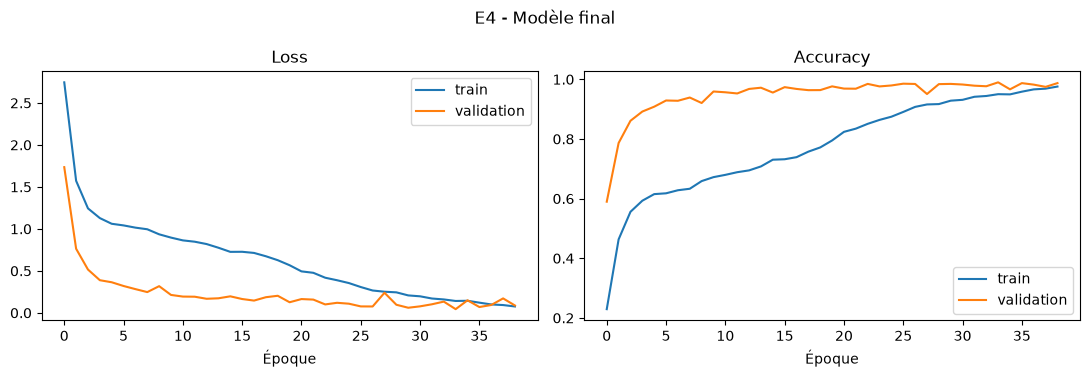

,expérience,modification,paramètres,époques,acc train (dernière),acc val (max),acc val (modèle conservé),loss val (modèle conservé),écart train - val,temps (s)
0,E0a - Dense,Flatten + Dense 256 + Dense 128 (référence),825131,15,0.9508,0.7914,0.7875,1.1641,0.1634,27
1,E0b - CNN de base,"3 blocs conv (32-64-128), Dense 128, Adam 1e-3...",554827,20,0.9927,0.9419,0.9367,0.3425,0.0560,284
2,E1 - Dropout,"Dropout 0,5 avant la sortie",554827,20,0.9937,0.9605,0.9507,0.2240,0.0430,260
3,E2 - Augmentation,Data Augmentation (sans flip),554827,20,0.9823,0.9545,0.9354,0.2854,0.0469,265
4,E3 - BatchNorm,BatchNormalization après chaque Conv,556619,20,1.0000,0.9850,0.9850,0.0660,0.0150,429
5,E4 - Modèle final,"Combinaison {'dropout': 0.5, 'augment': False,...",556619,39,0.9758,0.9899,0.9899,0.0438,-0.0114,789


In [15]:
# Choix des ingrédients du modèle final : on garde ce qui a battu le CNN de base en validation
acc = {r["expérience"]: r["acc val (modèle conservé)"] for r in RESULTS}
base = acc["E0b - CNN de base"]
final_kwargs = dict(dropout=0.5 if acc["E1 - Dropout"] > base else 0.0,
                    augment=acc["E2 - Augmentation"] > base,
                    batchnorm=acc["E3 - BatchNorm"] > base)
print("Ingrédients retenus pour E4 :", final_kwargs)

model, hist, dur = run_experiment("E4 - Modèle final", "Combinaison + EarlyStopping (patience 5)",
                                  build_kwargs=final_kwargs, epochs=40, early_stop=True)
results_df = log_result("E4 - Modèle final", "Combinaison " + str(final_kwargs) + " + EarlyStopping", hist, dur, model)
display(results_df)

Modèle retenu : E4 - Modèle final
[test] accuracy = 0.9766 | F1 macro = 0.9627


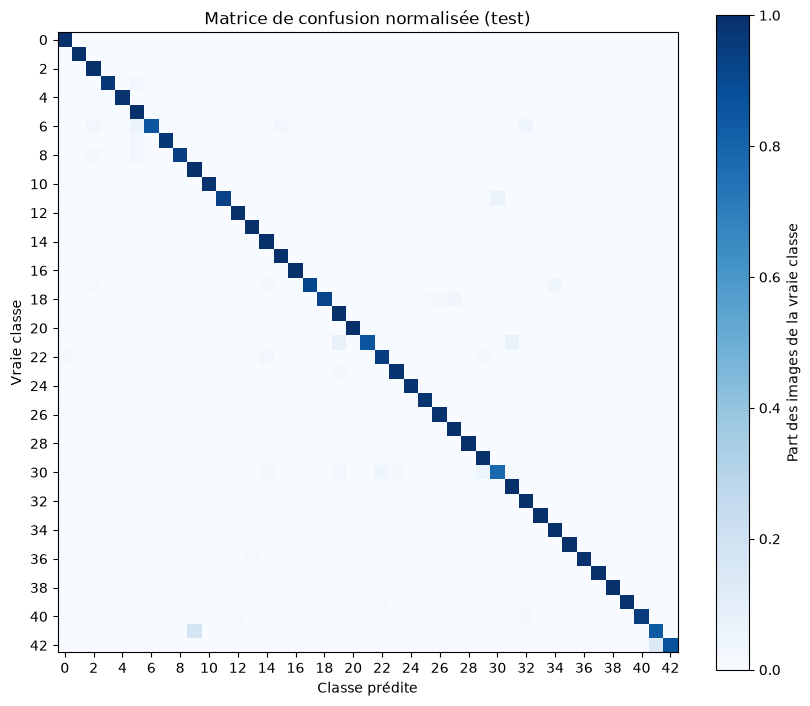


Classes les plus difficiles (recall le plus bas) :


,classe,support,recall,précision
30,30 - Risque de verglas,150,0.787,0.797
41,41 - Fin interdiction de dépasser,60,0.833,0.806
6,6 - Fin de limitation 80 km/h,150,0.853,0.992
21,21 - Succession de virages,90,0.856,1.000
42,42 - Fin interdiction de dépasser (poids lourds),90,0.867,1.000
17,17 - Sens interdit,360,0.911,0.991
18,18 - Danger général,390,0.918,0.992
11,11 - Priorité à la prochaine intersection,420,0.933,0.990


Paires de classes les plus confondues :


,vraie classe,prédite,nb erreurs
0,11 - Priorité à la prochaine intersection,30 - Risque de verglas,27
1,17 - Sens interdit,34 - Tourner à gauche obligatoire,14
2,7 - Limitation 100 km/h,5 - Limitation 80 km/h,13
3,8 - Limitation 120 km/h,5 - Limitation 80 km/h,13
4,18 - Danger général,27 - Passage piétons,13
5,3 - Limitation 60 km/h,5 - Limitation 80 km/h,13
6,42 - Fin interdiction de dépasser (poids lourds),41 - Fin interdiction de dépasser,12
7,41 - Fin interdiction de dépasser,9 - Interdiction de dépasser,10
8,18 - Danger général,26 - Feux tricolores,9
9,30 - Risque de verglas,29 - Cyclistes,9


Taux d'erreur par quartile de luminosité :


,taux d'erreur
niveau de luminosité,
très sombre,0.0291
sombre,0.0098
clair,0.0276
très clair,0.0269


Taux d'erreur par quartile de taille d'origine du panneau :


,taux d'erreur
taille d'origine,
"(24.999, 33.0]",0.0451
"(33.0, 42.0]",0.0160
"(42.0, 56.0]",0.0160
"(56.0, 232.0]",0.0162


Taux d'erreur par quartile de netteté (variance du Laplacien) :


,taux d'erreur
niveau de netteté,
très flou,0.0380
flou,0.0114
net,0.0266
très net,0.0174


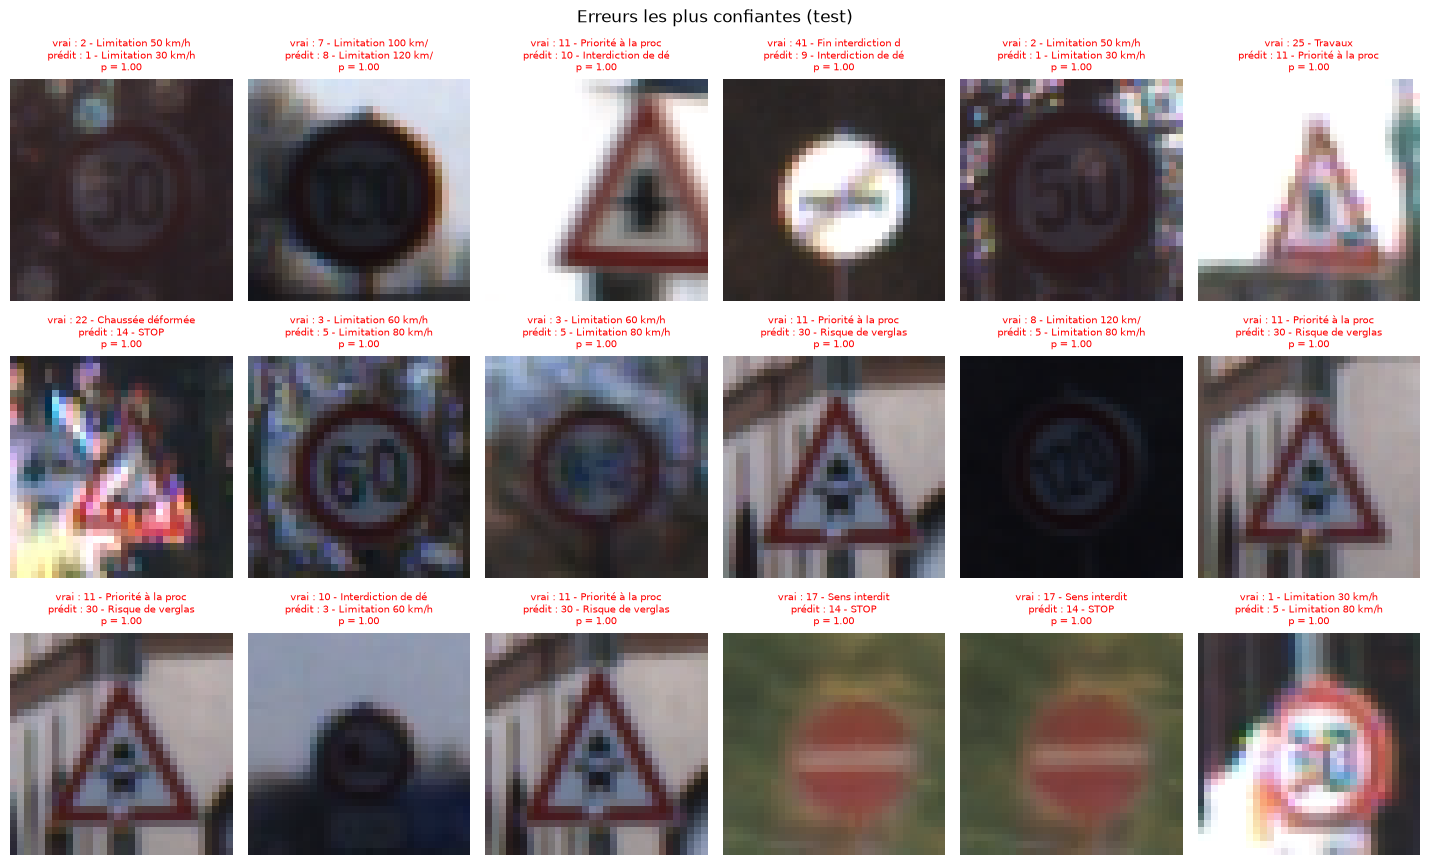

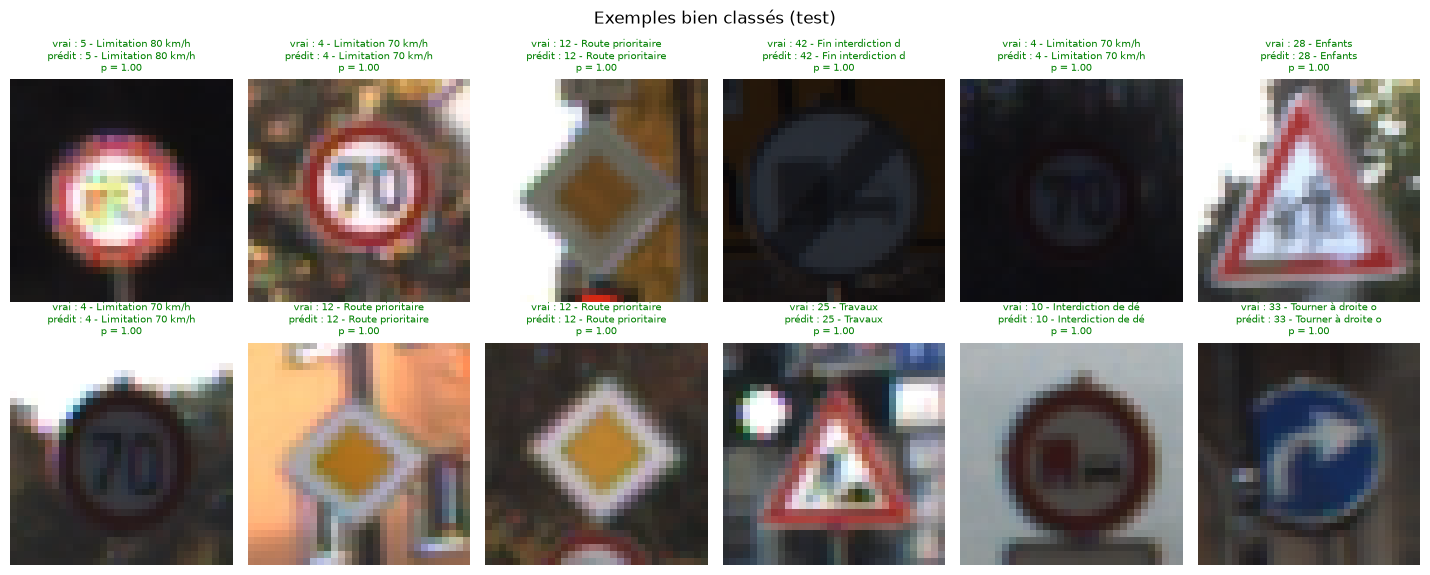

In [16]:
# Choix du modèle final : meilleure accuracy de validation (modèle réellement conservé)
best_name = results_df.sort_values("acc val (modèle conservé)").iloc[-1]["expérience"]
final_model = MODELS[best_name]
print("Modèle retenu :", best_name)

# Évaluation FINALE sur le test (à ne faire qu'une fois, après avoir figé tous les choix)
probs_test, pred_test, cm_test = analyze(final_model, X_test, y_test, sizes_test, "test")

**Justification du modèle final**

- **Modèle retenu : E4.** C'est le CNN à 3 blocs avec BatchNorm, Dropout 0,5 et Early Stopping. Il a la meilleure accuracy de validation (**99,0 %**) et la plus faible val_loss (**0,044**), pour seulement 1 792 paramètres de plus que le CNN de base (ceux de la BatchNorm). Le choix est fait **uniquement sur la validation** : le test n'a servi à aucune décision.

- **Validation et test.**

  | Mesure | Validation | Test |
  |---|---|---|
  | Accuracy | 99,0 % | **97,7 %** |
  | F1 macro | — | **0,963** |

  L'écart de 1,3 point est faible. Le modèle **généralise bien** à 12 630 images jamais vues, et notre validation découpée par piste, donc sans fuite, était une estimation assez fiable. Elle est légèrement optimiste, ce qui est attendu : c'est elle qui a servi à choisir le modèle. Par rapport au réseau dense de référence (78,8 % en validation), le gain total est d'environ **20 points**.

- **Erreurs restantes sur le test.** Ce sont les mêmes familles qu'en partie 5 :
  - **triangles de danger :** priorité à la prochaine intersection → risque de verglas (27 erreurs), danger général → passage piétons (13) ou feux tricolores (9), verglas → cyclistes (9) ;
  - **limitations de vitesse :** 60, 100 et 120 → 80 km/h (13 erreurs chacune) ;
  - **panneaux de fin d'interdiction**, barrés et grisés : 41 → 9 (10 erreurs), 42 → 41 (12 erreurs).

  La classe la plus difficile est **« risque de verglas »** (recall 79 %). Fait nouveau : « sens interdit » est parfois pris pour « tourner à gauche obligatoire » (14 erreurs). Les petits panneaux restent la principale source d'erreur : **4,5 %** d'erreurs pour le quart des panneaux de 33 px ou moins, contre 1,6 % pour les autres. Les images très floues (3,8 %) et très sombres (2,9 %) sont aussi un peu plus touchées.

- **Pistes d'amélioration :**
  - une résolution d'entrée plus grande (48×48) pour mieux lire les chiffres et les pictogrammes ;
  - la Data Augmentation sur plus d'époques ;
  - une pondération de la perte selon la fréquence des classes (`class_weight`), pour aider les classes rares ;
  - le Transfer Learning (réutiliser un réseau pré-entraîné).


## Démonstration : prédire sur une image

La fonction ci-dessous applique **exactement le même prétraitement** que celui de l'entraînement (taille 32×32, RGB, ÷ 255). C'est indispensable : une autre taille ou une autre normalisation rendrait les prédictions absurdes (et c'est la précaution clé si vous ajoutez plus tard un détecteur en amont).

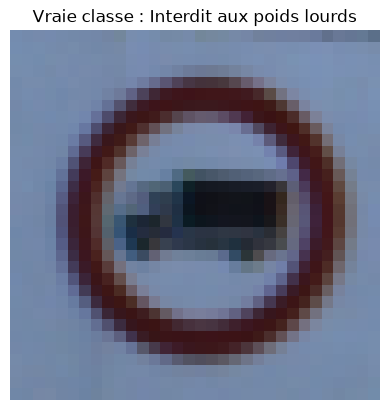

100.0%  16 - Interdit aux poids lourds
  0.0%   9 - Interdiction de dépasser
  0.0%  10 - Interdiction de dépasser (poids lourds)
Modèle sauvegardé : traffic_sign_cnn.keras


In [17]:
def preprocess_pil(img):
    arr = np.asarray(img.convert("RGB").resize((IMG, IMG), Image.BILINEAR), dtype=np.uint8)
    return arr.astype("float32") / 255.0


def predict_sign(model, img, top=3):
    p = model.predict(preprocess_pil(img)[None], verbose=0)[0]
    best = np.argsort(p)[::-1][:top]
    return [(int(c), CLASS_NAMES[c], float(p[c])) for c in best]


# Exemple sur une image du test
i = 0
img = Image.fromarray(X_test_u8[i])
plt.imshow(img); plt.axis("off"); plt.title(f"Vraie classe : {CLASS_NAMES[y_test[i]]}"); plt.show()
for c, nom, prob in predict_sign(final_model, img):
    print(f"{prob:6.1%}  {c:2d} - {nom}")

# Sauvegarde du modèle (pour la démonstration, sans ré-entraîner)
final_model.save("traffic_sign_cnn.keras")
print("Modèle sauvegardé : traffic_sign_cnn.keras")

# Synthèse du projet

**Le système en une phrase :** un CNN Keras reçoit une image de panneau (32×32, RGB, pixels ÷ 255) et donne une probabilité pour chacune des 43 classes de GTSRB. La classe prédite est celle de plus forte probabilité. Le modèle final atteint **97,7 % d'accuracy sur le test** (F1 macro 0,963).

| Étape | Résultat clé |
|---|---|
| Données | 39 270 images, 43 classes, déséquilibre de 1 à 10 ; validation découpée **par piste** pour éviter la fuite de données |
| Réseau dense (référence) | 78,8 % en validation, fort surapprentissage (16 points d'écart) |
| CNN de base | 93,7 % en validation (+15 points) avec 33 % de paramètres en moins |
| Expériences | Dropout +1,4 point ; Data Augmentation sans gain en 20 époques ; **BatchNorm +4,8 points** |
| Modèle final | Dropout + BatchNorm + Early Stopping : 99,0 % en validation, **97,7 % sur le test** |

**Ce qu'on retient :**
- **La convolution change tout par rapport au réseau dense :** les poids sont partagés sur toute l'image et le réseau exploite le voisinage des pixels.
- **La BatchNorm a été la modification la plus efficace**, car elle stabilise l'apprentissage.
- **Les erreurs restantes viennent surtout :**
  - de la ressemblance entre classes (limitations de vitesse entre elles, triangles de danger entre eux) ;
  - de la petite taille des panneaux (4,5 % d'erreurs pour les plus petits, contre 1,6 % pour les autres) ;
  - du manque d'exemples pour les classes rares.
- **L'accuracy seule ne suffit pas** sur des classes déséquilibrées : il faut aussi regarder la matrice de confusion, le recall par classe et le F1 macro.

**Limites :**
- une seule graine aléatoire par expérience : des écarts d'environ 1 point peuvent être du bruit ;
- certaines classes n'ont qu'une piste (30 images) en validation, ce qui rend leur recall très variable.
